## Edge Retention and Weight Stability Across Random Seeds

Run sparsification across multiple seeds with a fixed sample count, tracking each edge’s retention frequency and mean sampled weight using method = "sum".

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sparsification import *

  edge  runs_retained  retention_percent  original_weight  total_weight  mean_weight
 t2-t3           6055              60.55           21.632    217351.433       21.735
t7-t10           4796              47.96           14.134    142063.054       14.206
 t5-t8           4576              45.76           13.584    133516.437       13.352
 t4-t9           4530              45.30           13.042    128451.740       12.845
 t1-t5           4477              44.77           12.562    125700.216       12.570
 t1-t8           4311              43.11           12.562    122311.133       12.231
 t4-t6           4315              43.15           11.908    120683.437       12.068
 t6-t9           4242              42.42           11.908    118115.705       11.812
t8-t10           3609              36.09            9.056     92595.054        9.260
 t1-t7           3611              36.11            9.207     92398.645        9.240
t1-t10           3582              35.82            9.207     922

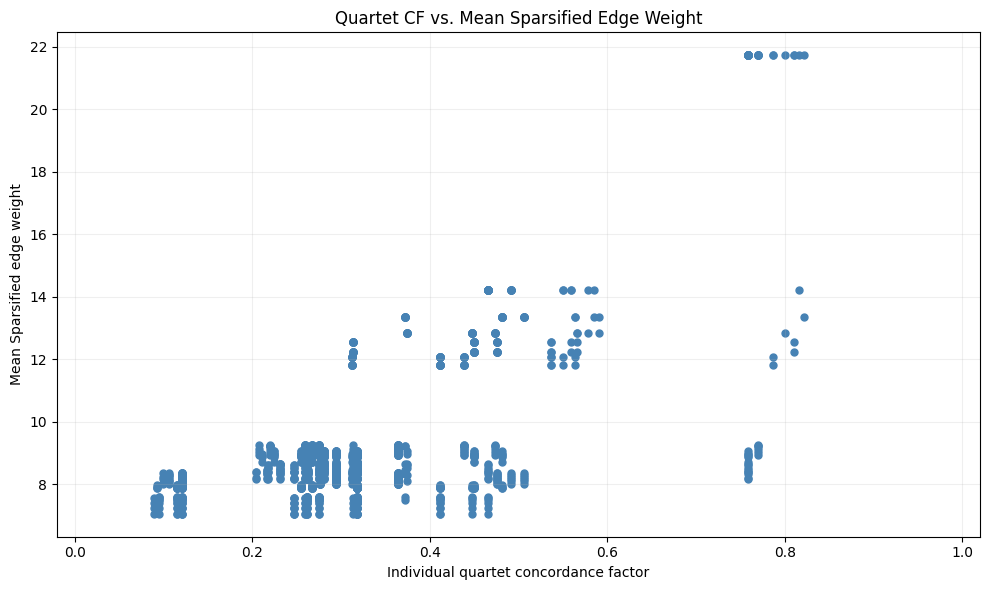

In [2]:
df = pd.read_csv("dfs.csv")
T, taxa = build_tensor(df)

num_seeds = 10000
method = "sum"
num_samples = 20

W = collapse_tensor(T, method)
L = compute_laplacian(W)
R = compute_effective_resistance(L)
edge_list = compute_edge_sampling_probabilities(W, R, taxa)

# Each edge gets a list containing its weight from every run
weights_by_edge = {
    (i, j): []
    for i, j, w, r, s, p in edge_list
}

for seed in range(num_seeds):
    W_sparse = sample_edges(
        edge_list,
        num_samples=num_samples,
        n=len(taxa),
        taxa=taxa,
        seed=seed
    )

    for i, j in weights_by_edge:
        # Includes zero when the edge wasn't retained
        weights_by_edge[(i, j)].append(W_sparse[i, j])

# Summarize results for each edge
rows = []

W_mean = np.zeros_like(W, dtype=float)

for (i, j), weights in weights_by_edge.items():
    weights = np.array(weights)
    count = np.count_nonzero(weights > 0)
    mean_weight = np.mean(weights)

    W_mean[i, j] = mean_weight
    W_mean[j, i] = mean_weight

    rows.append({
        "edge": f"{taxa[i]}-{taxa[j]}",
        "runs_retained": count,
        "retention_percent": 100 * count / num_seeds,
        "original_weight": W[i, j],
        "total_weight": np.sum(weights),
        "mean_weight": mean_weight
    })

weight_df = (
    pd.DataFrame(rows)
    .sort_values("mean_weight", ascending=False)
    .reset_index(drop=True)
)

print(weight_df.round(3).to_string(index=False))
plot_cf_vs_sparse_weights(df, W_mean, taxa)

Run sparsification across multiple seeds with a fixed sample count, tracking each edge’s retention frequency and mean sampled weight using method = "max".

In [3]:
df = pd.read_csv("dfs.csv")
T, taxa = build_tensor(df)

num_seeds = 1000
method = "max"
num_samples = 20

W = collapse_tensor(T, method)
L = compute_laplacian(W)
R = compute_effective_resistance(L)
edge_list = compute_edge_sampling_probabilities(W, R, taxa)

# Each edge gets a list containing its weight from every run
weights_by_edge = {
    (i, j): []
    for i, j, w, r, s, p in edge_list
}

for seed in range(num_seeds):
    W_sparse = sample_edges(
        edge_list,
        num_samples=num_samples,
        n=len(taxa),
        taxa=taxa,
        seed=seed
    )

    for i, j in weights_by_edge:
        # Includes zero when the edge wasn't retained
        weights_by_edge[(i, j)].append(W_sparse[i, j])

# Summarize results for each edge
rows = []

for (i, j), weights in weights_by_edge.items():
    weights = np.array(weights)
    count = np.count_nonzero(weights > 0)

    rows.append({
        "edge": f"{taxa[i]}-{taxa[j]}",
        "runs_retained": count,
        "retention_percent": 100 * count / num_seeds,
        "original_weight": W[i, j],
        "total_weight": np.sum(weights),
        "mean_weight": np.mean(weights)
    })

weight_df = (
    pd.DataFrame(rows)
    .sort_values("mean_weight", ascending=False)
    .reset_index(drop=True)
)

print(weight_df.round(3).to_string(index=False))

  edge  runs_retained  retention_percent  original_weight  total_weight  mean_weight
t7-t10            410               41.0            0.816       861.231        0.861
 t4-t9            414               41.4            0.800       846.426        0.846
 t4-t6            409               40.9            0.787       834.408        0.834
t9-t10            383               38.3            0.759       812.587        0.813
 t4-t7            395               39.5            0.759       810.981        0.811
 t2-t3            492               49.2            0.821       808.897        0.809
 t6-t8            402               40.2            0.759       807.767        0.808
 t5-t8            398               39.8            0.821       797.130        0.797
 t8-t9            380               38.0            0.759       794.041        0.794
 t1-t5            400               40.0            0.810       790.454        0.790
 t1-t8            392               39.2            0.810       7

Run sparsification across multiple seeds with a fixed sample count, tracking each edge’s retention frequency and mean sampled weight using method = "mean".

In [4]:
df = pd.read_csv("dfs.csv")
T, taxa = build_tensor(df)

num_seeds = 1000
method = "mean"
num_samples = 20

W = collapse_tensor(T, method)
L = compute_laplacian(W)
R = compute_effective_resistance(L)
edge_list = compute_edge_sampling_probabilities(W, R, taxa)

# Each edge gets a list containing its weight from every run
weights_by_edge = {
    (i, j): []
    for i, j, w, r, s, p in edge_list
}

for seed in range(num_seeds):
    W_sparse = sample_edges(
        edge_list,
        num_samples=num_samples,
        n=len(taxa),
        taxa=taxa,
        seed=seed
    )

    for i, j in weights_by_edge:
        # Includes zero when the edge wasn't retained
        weights_by_edge[(i, j)].append(W_sparse[i, j])

# Summarize results for each edge
rows = []

for (i, j), weights in weights_by_edge.items():
    weights = np.array(weights)
    count = np.count_nonzero(weights > 0)

    rows.append({
        "edge": f"{taxa[i]}-{taxa[j]}",
        "runs_retained": count,
        "retention_percent": 100 * count / num_seeds,
        "original_weight": W[i, j],
        "total_weight": np.sum(weights),
        "mean_weight": np.mean(weights)
    })

weight_df = (
    pd.DataFrame(rows)
    .sort_values("mean_weight", ascending=False)
    .reset_index(drop=True)
)

print(weight_df.round(3).to_string(index=False))

  edge  runs_retained  retention_percent  original_weight  total_weight  mean_weight
 t2-t3            611               61.1            0.103       100.841        0.101
t7-t10            489               48.9            0.067        70.656        0.071
 t4-t6            463               46.3            0.057        63.397        0.063
 t5-t8            442               44.2            0.065        63.046        0.063
 t4-t9            453               45.3            0.062        62.280        0.062
 t1-t5            452               45.2            0.060        58.347        0.058
 t1-t8            433               43.3            0.060        56.485        0.056
 t6-t9            434               43.4            0.057        56.102        0.056
t9-t10            353               35.3            0.042        45.527        0.046
t6-t10            362               36.2            0.043        44.340        0.044
 t6-t7            361               36.1            0.043        

Run sparsification across multiple seeds with a fixed sample count, tracking each edge’s retention frequency and mean sampled weight using method = "l2".

In [5]:
df = pd.read_csv("dfs.csv")
T, taxa = build_tensor(df)

num_seeds = 1000
method = "l2"
num_samples = 20

W = collapse_tensor(T, method)
L = compute_laplacian(W)
R = compute_effective_resistance(L)
edge_list = compute_edge_sampling_probabilities(W, R, taxa)

# Each edge gets a list containing its weight from every run
weights_by_edge = {
    (i, j): []
    for i, j, w, r, s, p in edge_list
}

for seed in range(num_seeds):
    W_sparse = sample_edges(
        edge_list,
        num_samples=num_samples,
        n=len(taxa),
        taxa=taxa,
        seed=seed
    )

    for i, j in weights_by_edge:
        # Includes zero when the edge wasn't retained
        weights_by_edge[(i, j)].append(W_sparse[i, j])

# Summarize results for each edge
rows = []

for (i, j), weights in weights_by_edge.items():
    weights = np.array(weights)
    count = np.count_nonzero(weights > 0)

    rows.append({
        "edge": f"{taxa[i]}-{taxa[j]}",
        "runs_retained": count,
        "retention_percent": 100 * count / num_seeds,
        "original_weight": W[i, j],
        "total_weight": np.sum(weights),
        "mean_weight": np.mean(weights)
    })

weight_df = (
    pd.DataFrame(rows)
    .sort_values("mean_weight", ascending=False)
    .reset_index(drop=True)
)

print(weight_df.round(3).to_string(index=False))

  edge  runs_retained  retention_percent  original_weight  total_weight  mean_weight
 t2-t3            595               59.5            4.089      4067.602        4.068
t7-t10            482               48.2            2.698      2860.723        2.861
 t4-t6            453               45.3            2.312      2576.044        2.576
 t5-t8            432               43.2            2.613      2543.595        2.544
 t4-t9            438               43.8            2.509      2499.319        2.499
 t1-t5            445               44.5            2.437      2378.571        2.379
 t1-t8            429               42.9            2.437      2322.756        2.323
 t6-t9            429               42.9            2.312      2272.729        2.273
t9-t10            353               35.3            1.768      1904.293        1.904
t6-t10            358               35.8            1.795      1866.470        1.866
 t6-t7            365               36.5            1.795      18